<div style="background:linear-gradient(90deg,#1f5fa8,#1e7a45); padding:18px 22px; border-radius:8px; color:white;">
<h1 style="color:white; margin:0;">Data, Least-Squares Baseline and Validation</h1>
<p style="margin:6px 0 0 0;">MAC F314 Mathematical Modelling &middot; Canadian lynx&ndash;snowshoe hare &middot; Owner: Advay</p>
</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">What this notebook does</b>

1. **Data.** Loads the Hudson's Bay Company pelt counts (1900–1920), checks them and explains what they mean.
2. **Least squares.** Fits the shared Rosenzweig–MacArthur model to 1900–1915 by bounded nonlinear least squares.
3. **Validation.** Scores frozen forecasts from least squares and Yash's PINN on the held-out years 1916–1920.

Every choice that could be influenced by the held-out years was committed to git **before** those years were opened:
`docs/advay_baseline_protocol.md` and `docs/advay_scoring_plan.md`.

</div>

In [1]:
import json, csv, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from lynx_hare.data import read_training
from lynx_hare.model import Parameters, solve
from lynx_hare import historical_ls as hls, stability as st

DATA, RES = ROOT / "data" / "historical", ROOT / "results" / "historical"
config = json.loads((ROOT / "configs" / "historical.json").read_text())
print("Project root:", ROOT)

Project root: /home/advay/Documents/Code/Lynx-Hare-Project-Mathematical-Modelling


## 1. The data

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Source and meaning</b>

Annual **thousands of pelts traded** by the Hudson's Bay Company, from the Stan case study (Carpenter, 2018). They are trade counts, **not censuses**.

**Assumption O1:** pelts are proportional to abundance, with unknown constant factors. The model states $H,P$ are defined directly in pelt units:

$$Y_{H,i} = H(t_i) + \varepsilon_{H,i}, \qquad Y_{P,i} = P(t_i) + \varepsilon_{P,i}, \qquad t_i = \text{Year}_i - 1900.$$

So $K,b,a,e$ are *effective* coefficients in pelt units. Only $r$, $m$ and the dimensionless groups have a biological reading.

</div>

In [2]:
split = json.loads((DATA / "split.json").read_text())
train = read_training(DATA / split["train"]["file"], 1900, 1915)   # only the training file
print("Training rows:", len(train.years), " years", int(train.years[0]), "-", int(train.years[-1]))
print("Scale (training maxima):", train.scale, "  initial state:", train.initial_state)
print("Train file sha256 matches split record:",
      __import__("hashlib").sha256((DATA / split["train"]["file"]).read_bytes()).hexdigest() == split["train"]["sha256"])

Training rows: 16  years 1900 - 1915
Scale (training maxima): [77.4 59.4]   initial state: [30.  4.]
Train file sha256 matches split record: True


### Checks on the training years (from `scripts/advay_data_checks.py`)

Integrity: {'n_rows': 21, 'years': [1900, 1920], 'consecutive_years': True, 'duplicate_years': 0, 'missing_values': 0, 'nonpositive_values': 0}
Hare peaks: [1903, 1913]  Lynx peaks: [1904]
Best lag (lynx after hare): 2 years, r = 0.943
Outliers flagged: [] []


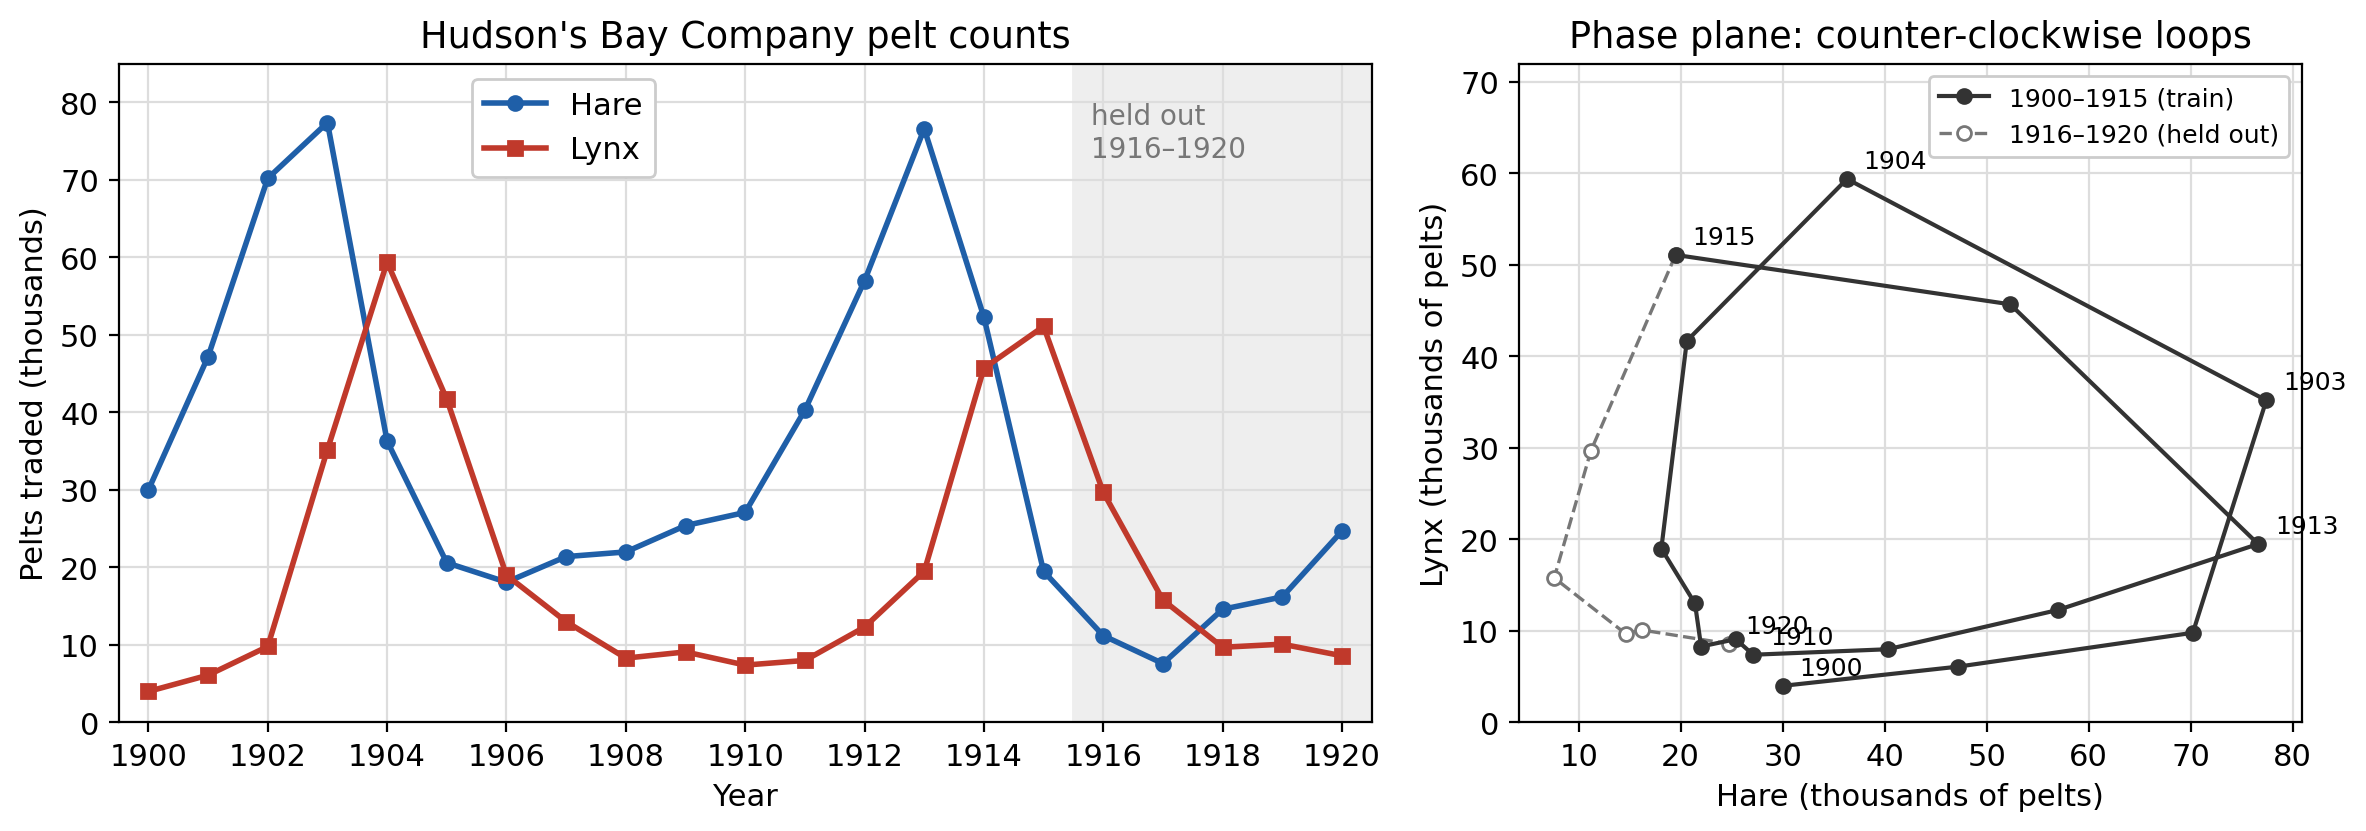

In [3]:
checks = json.loads((RES / "data_checks" / "summary.json").read_text())
t = checks["training"]
print("Integrity:", checks["integrity"])
print("Hare peaks:", t["hare_peaks"], " Lynx peaks:", t["lynx_peaks"])
print("Best lag (lynx after hare):", t["best_lag_years"], "years, r =", t["cross_correlation"][str(t["best_lag_years"])])
print("Outliers flagged:", t["outliers_hare"]["flagged"], t["outliers_lynx"]["flagged"])
display(Image(str(RES / "data_checks" / "figures" / "advay_raw_series.png"), width=900))

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Two compilations disagree</b>

The tsibbledata `pelt` series covers the same records but differs year by year (hare correlation 0.32). All results are conditional on the Stan series.

</div>

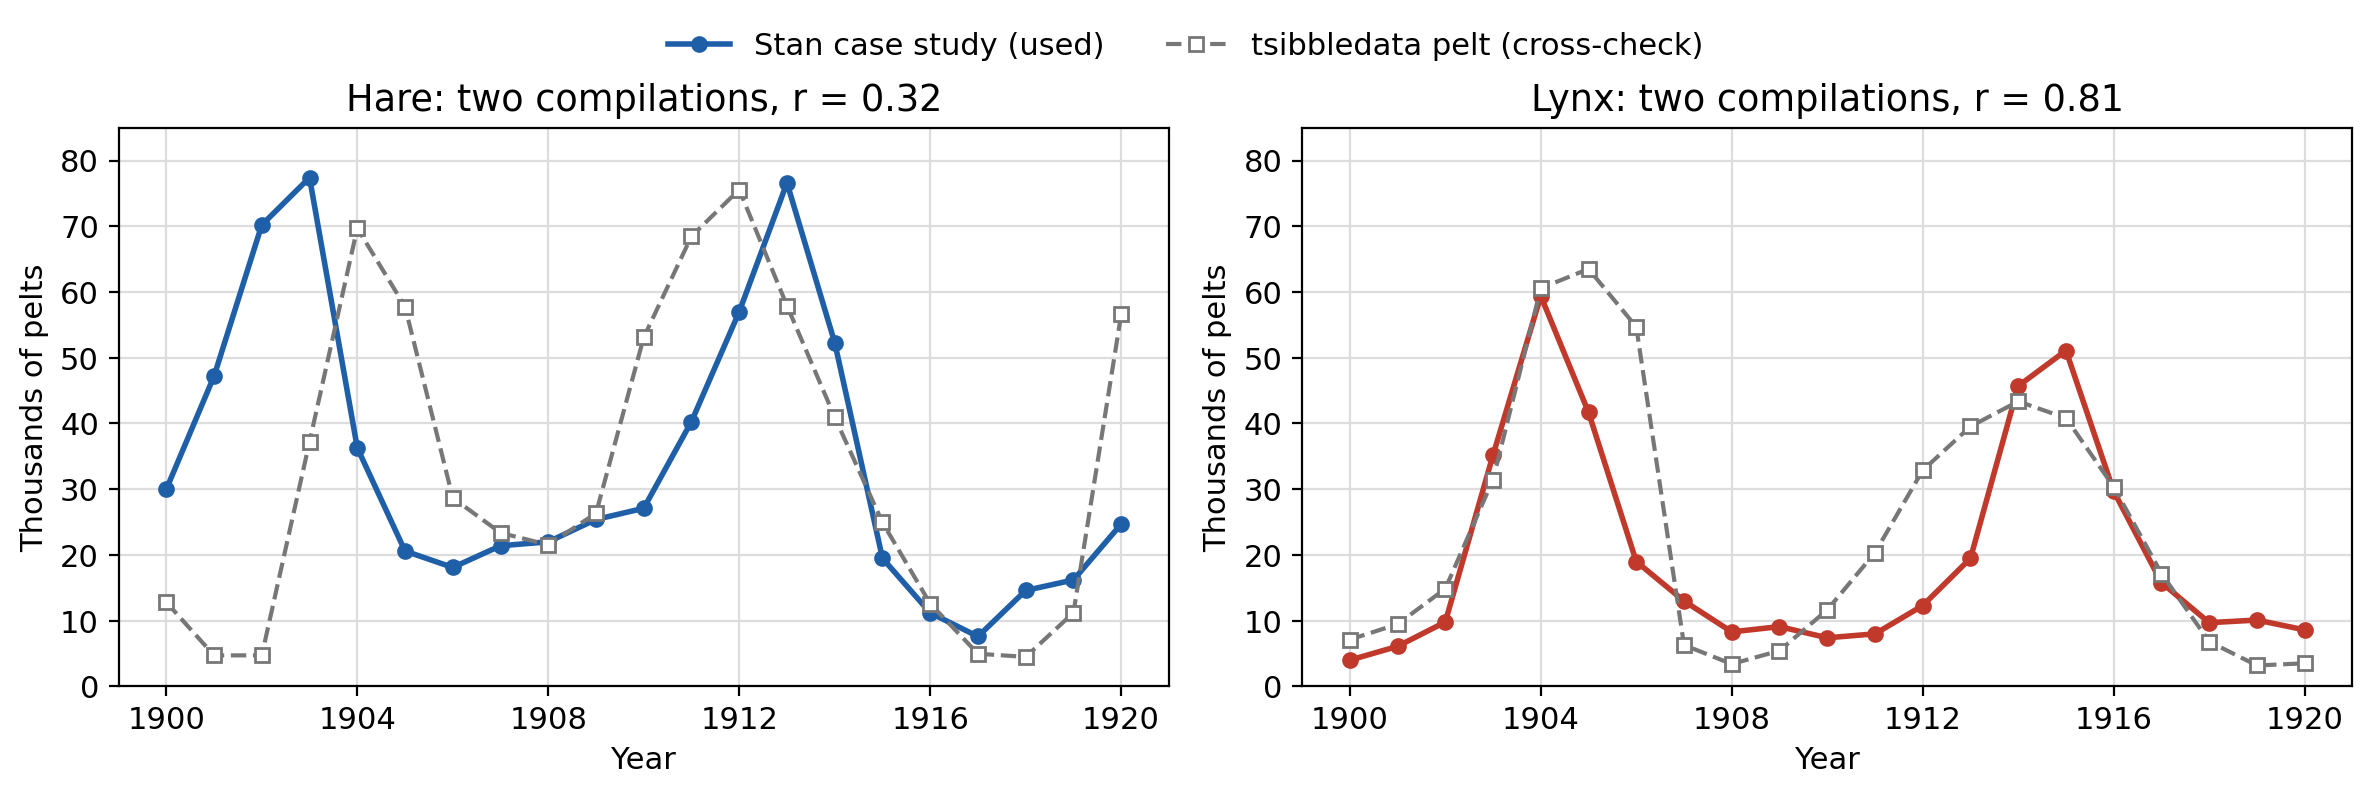

In [4]:
display(Image(str(RES / "data_checks" / "figures" / "advay_source_comparison.png"), width=900))

## 2. Least-squares baseline

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">The fitting problem</b>

With $\\theta=(r,K,a,b,e,m)$, solve

$$\\dot H = rH\\Big(1-\\frac{H}{K}\\Big) - \\frac{aHP}{b+H}, \\qquad \\dot P = \\frac{eaHP}{b+H} - mP$$

from the observed 1900 state with RK45 (rtol $10^{-8}$, atol $10^{-10}$, max step 0.1 yr), and minimise

$$C(\\theta) = \\tfrac12 \\sum_{i=1900}^{1915} \\Big[\\Big(\\tfrac{\\hat H_i - Y_{H,i}}{77.4}\\Big)^2 + \\Big(\\tfrac{\\hat P_i - Y_{P,i}}{59.4}\\Big)^2\\Big]$$

within the shared bounds in `configs/historical.json`.

**Algorithm**
1. Work in $x = \\log\\theta$, because the bounds span up to 600-fold.
2. From each start, run SciPy's bounded trust-region reflective least squares.
3. Use 80 starts per variant: the config guess, 39 Latin-hypercube points uniform in $\\log\\theta$, and 39 uniform in $\\theta$.
4. Keep the lowest training cost.

The two sensitivity variants change one assumption each: log residuals; or fitted $(H_0,P_0)$.

</div>

### Two starts, live: why many starts are needed (the full 240-start run takes about 20 minutes and is loaded below)

In [5]:
problem = hls.Problem(train, config, "main")
settings = {"diff_step": 1e-4, "max_nfev": 2000, "ftol": 1e-10, "xtol": 1e-10, "gtol": 1e-10}
starts = hls.starting_points(problem, 40, 20261027 + 100, "linear")   # v2's ordinary-scale starts (main variant)
for i in (2, 29):
    fit = hls.fit_start(problem, starts[i], settings)
    print(f"start {i:2d}: training cost {fit.cost:.4f}  ",
          {k: round(v, 3) for k, v in problem.unpack(fit.x)[0].to_dict().items()})
print("Start 29 stops in a local minimum about 9x worse than start 2, which reaches the best fit.")

start  2: training cost 0.0845   {'r': 0.647, 'K': 382.426, 'a': 10.0, 'b': 300.0, 'e': 0.967, 'm': 0.857}


start 29: training cost 0.7418   {'r': 2.299, 'K': 83.886, 'a': 2.839, 'b': 20.523, 'e': 1.717, 'm': 3.0}
Start 29 stops in a local minimum about 9x worse than start 2, which reaches the best fit.


variant            cost      r       K      a      b      e      m  sigma  regime  near-best  at bound
main             0.0845  0.647   382.4  10.00  300.0  0.967  0.857  1.067  limit_cycle  18/80  {'a': 'upper', 'b': 'upper'}
log_errors       0.9033  0.520   197.1   7.17  300.0  1.797  1.148  0.550  stable_coexistence  42/78  {'b': 'upper'}
fitted_initial   0.0634  0.520   362.4   8.15  300.0  1.317  1.048  0.993  stable_coexistence  16/80  {'b': 'upper'}


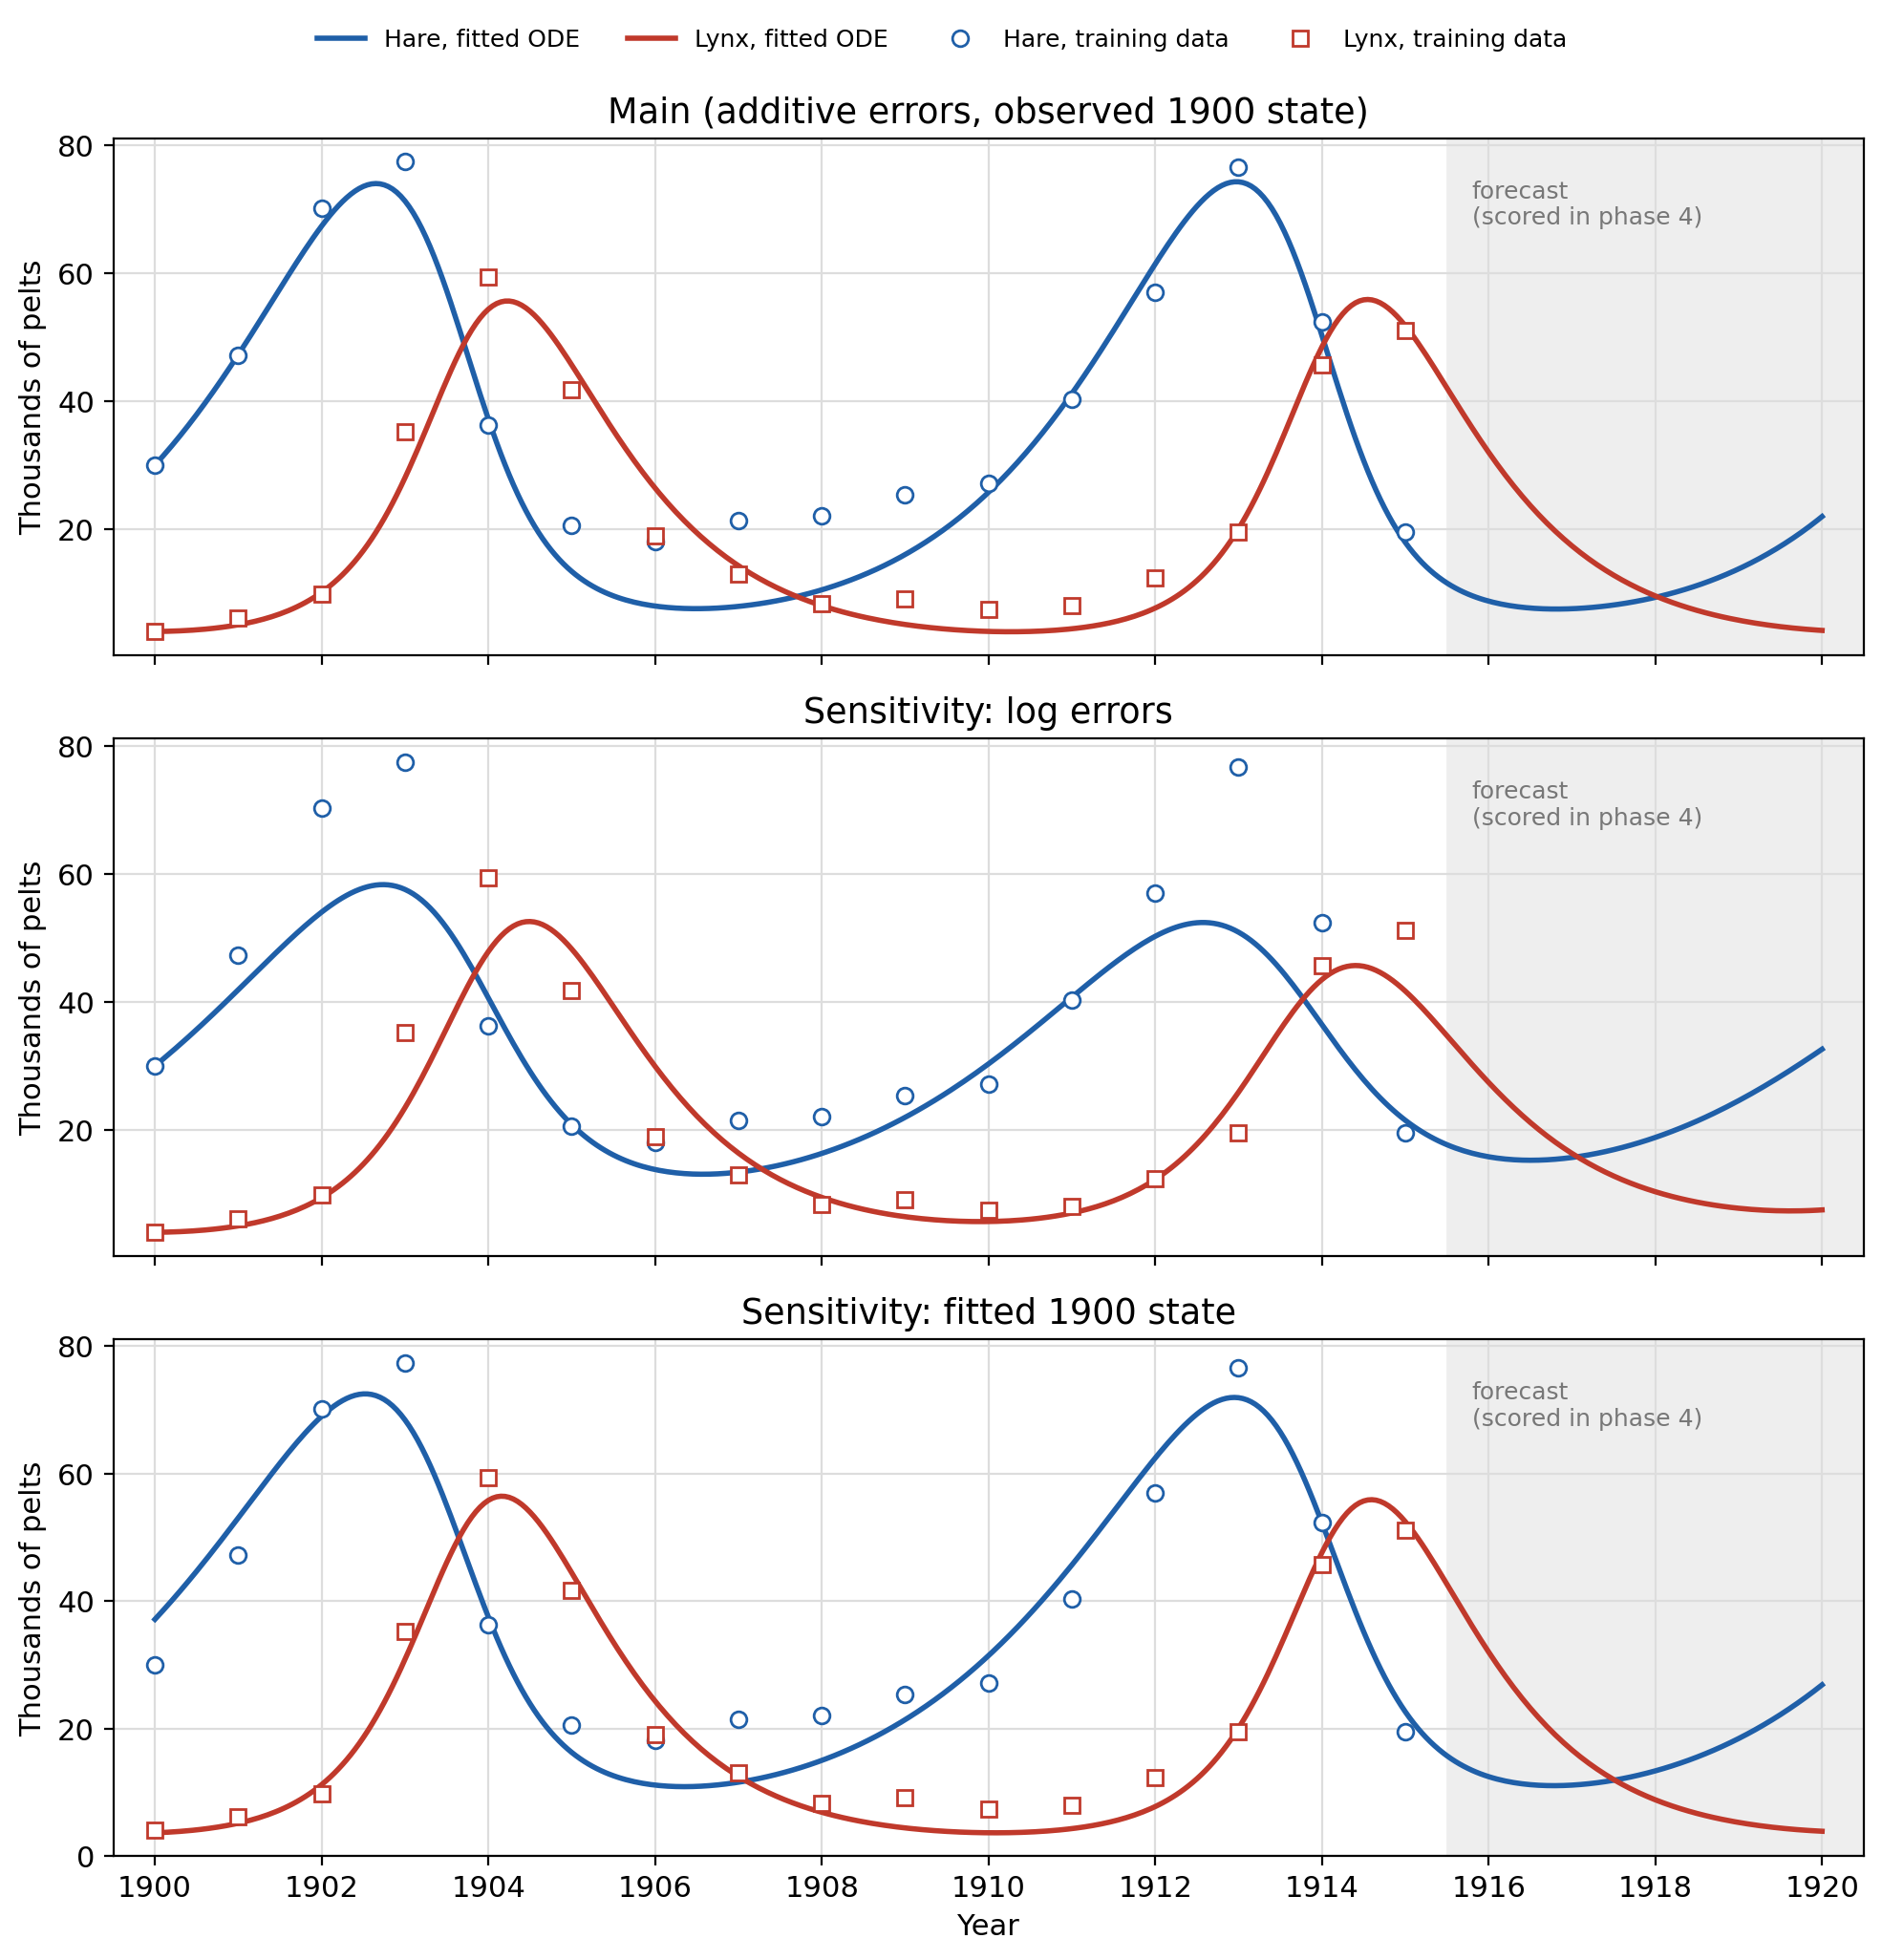

In [6]:
sel = json.loads((RES / "advay_baseline_v2" / "selected.json").read_text())
rows = []
for v, s in sel.items():
    p = s["parameters"]
    rows.append([v, round(s["cost"], 4), *[round(p[k], 3) for k in ("r", "K", "a", "b", "e", "m")],
                 round(s["sigma"], 3), s["regime"], f'{s["starts_near_best"]}/{s["starts_ok"]}', s["at_bound"]])
print(f'{"variant":15s} {"cost":>7s} {"r":>6s} {"K":>7s} {"a":>6s} {"b":>6s} {"e":>6s} {"m":>6s} {"sigma":>6s}  regime  near-best  at bound')
for r in rows:
    print(f"{r[0]:15s} {r[1]:7.4f} {r[2]:6.3f} {r[3]:7.1f} {r[4]:6.2f} {r[5]:6.1f} {r[6]:6.3f} {r[7]:6.3f} {r[8]:6.3f}  {r[9]}  {r[10]}  {r[11]}")
display(Image(str(RES / "advay_baseline_v2" / "figures" / "advay_baseline_fit.png"), width=800))

<div style="background:#fdecea; border-left:6px solid #b03a2e; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b03a2e; font-size:1.1em;">What the fit can and cannot tell us</b>

- **Well defined.** Every start within 1% of the best cost found the same parameters, and Yash's independent least-squares code reaches the same optimum.
- **Saturation not identified.** $b$ hits its upper bound (300 ≫ max hare 77.4), so $aH/(b+H)\\approx (a/b)H$. Only $a/b$ is well determined.
- **Cycle vs damped is undecided.** $\\sigma = K/K_H$ is 1.07, 0.99 or 0.55 depending on the observation assumption, yet all three fit the peak timing.

</div>

Approx. log-parameter standard errors: {'r': 0.2, 'K': 1.09, 'a': 1.18, 'b': 1.38, 'e': 0.15, 'm': 0.1}
Strongest correlations: [(['a', 'b'], 0.998), (['K', 'b'], 0.975), (['K', 'a'], 0.971)]


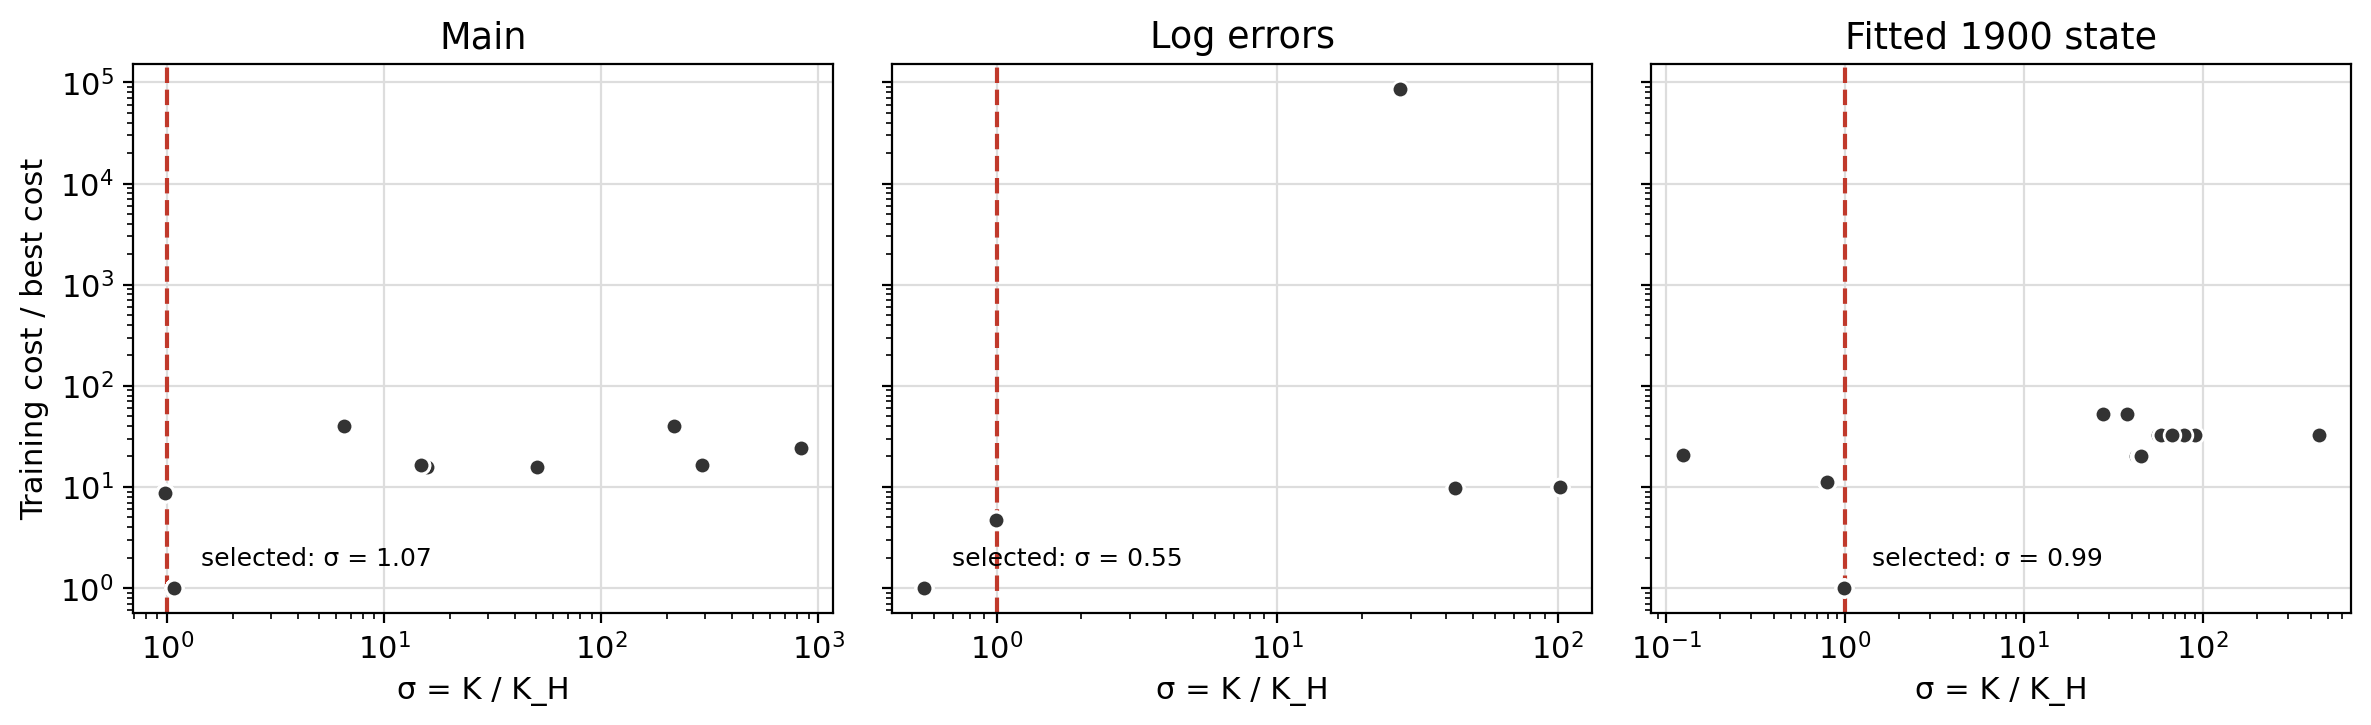

In [7]:
ident = sel["main"]["identifiability"]
print("Approx. log-parameter standard errors:", {k: round(v, 2) for k, v in ident["approx_log_parameter_se"].items()})
print("Strongest correlations:", [(c["pair"], round(c["abs_corr"], 3)) for c in ident["strongest_correlations"][:3]])
display(Image(str(RES / "advay_baseline_v2" / "figures" / "advay_baseline_sigma.png"), width=900))

## 3. Held-out evaluation, 1916–1920

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Scoring rules (declared before opening the test file)</b>

- RMSE and MAE for **each species separately**, in thousands of pelts.
- A method is called **better** only if both of its errors are smaller **and** it is closer in at least 3 of the 5 years; otherwise **similar**.
- Reference forecasts, built from training data only: hold the 1915 value; use the training mean.

</div>

In [8]:
metrics = list(csv.DictReader(open(RES / "advay_evaluation_v1" / "metrics.csv")))
comparison = json.loads((RES / "advay_evaluation_v1" / "comparison.json").read_text())
show = [("LS-Advay", "main"), ("PINN", "main_seed17"), ("Persistence (1915 value)", "-"), ("Training mean", "-")]
for m in metrics:
    if (m["label"], m["run"] if m["label"] == "PINN" else m["variant"]) in show or (m["label"] == "LS-Advay" and m["variant"] == "main"):
        if m["label"] == "PINN" and m["run"] != "main_seed17":
            continue
        print(f'{m["label"]:26s} hare RMSE {float(m["hare_rmse"]):6.2f} MAE {float(m["hare_mae"]):6.2f} | '
              f'lynx RMSE {float(m["lynx_rmse"]):6.2f} MAE {float(m["lynx_mae"]):6.2f}')
for v, c in comparison.items():
    print(f'{v:15s} ({c["status"]}): hare {c["hare_verdict"]}, lynx {c["lynx_verdict"]}')

LS-Advay                   hare RMSE   3.07 MAE   2.59 | lynx RMSE   3.04 MAE   2.56
PINN                       hare RMSE   2.85 MAE   2.59 | lynx RMSE   4.32 MAE   4.05
Persistence (1915 value)   hare RMSE   7.38 MAE   6.72 | lynx RMSE  37.16 MAE  36.32
Training mean              hare RMSE  25.87 MAE  25.23 | lynx RMSE  10.58 MAE  10.21
main            (headline): hare similar, lynx LS better
log_errors      (sensitivity): hare LS better, lynx LS better
fitted_initial  (sensitivity): hare similar, lynx LS better


### Independent recomputation in this notebook

Least squares, main    RMSE hare 3.072 lynx 3.043 | MAE hare 2.587 lynx 2.559
PINN, main seed 17     RMSE hare 2.847 lynx 4.317 | MAE hare 2.590 lynx 4.046


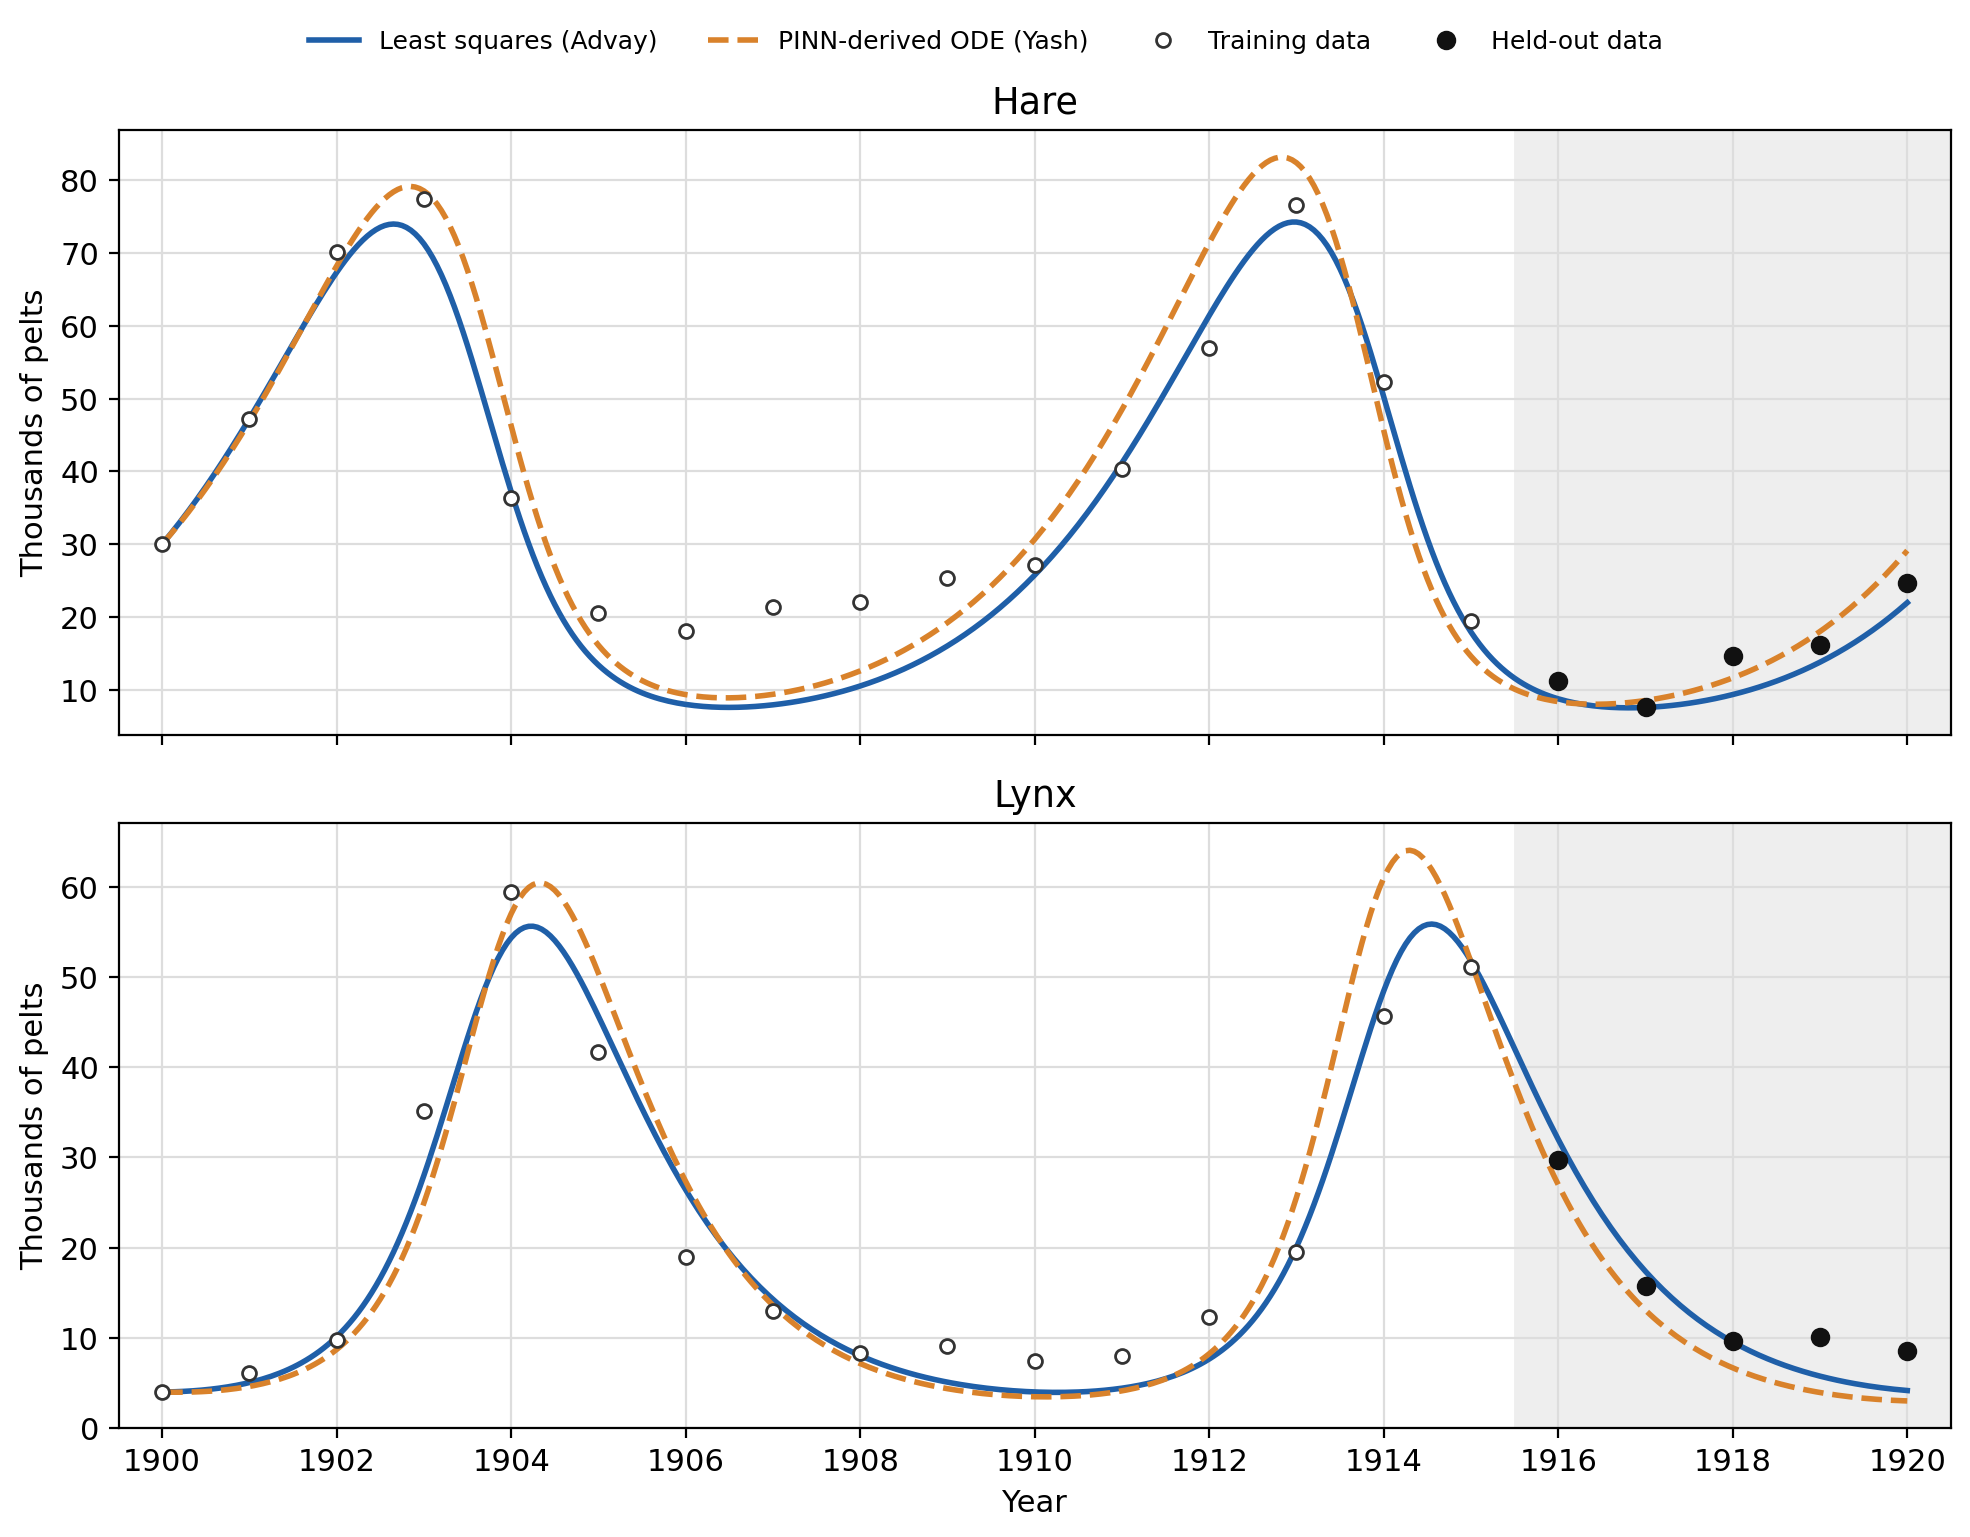

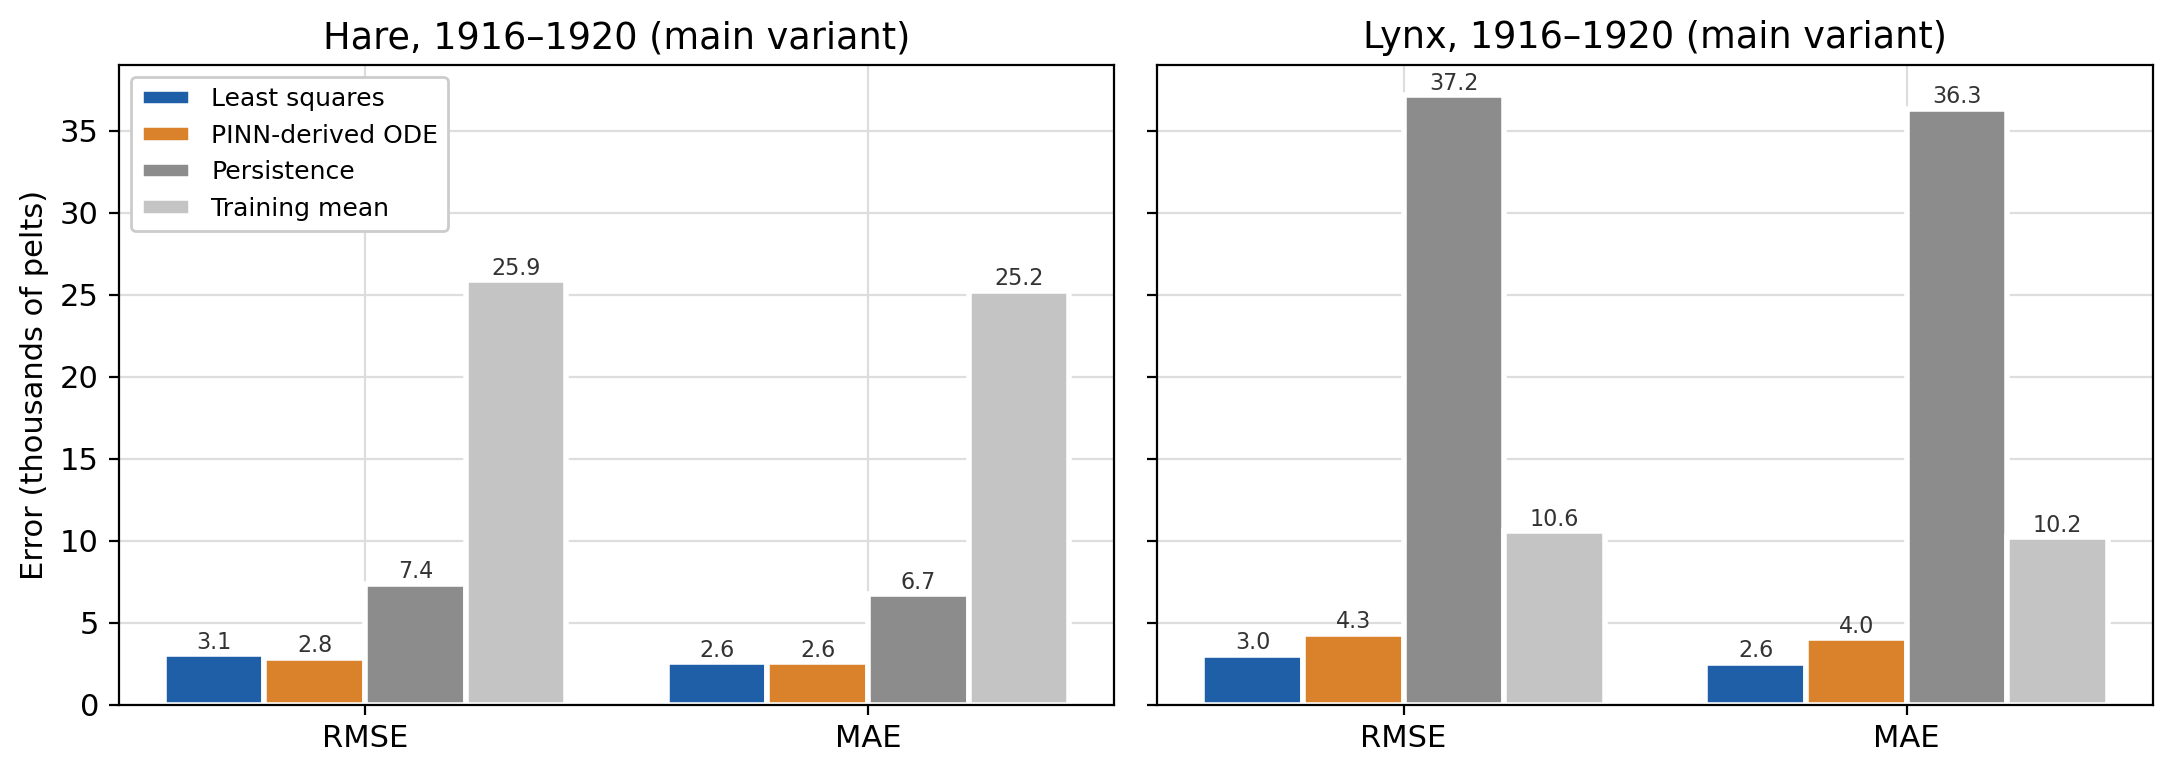

In [9]:
test = np.array([[float(x) for x in r.values()] for r in csv.DictReader(open(DATA / "test_1916_1920.csv"))])
def score(path):
    f = np.array([[float(x) for x in r.values()] for r in csv.DictReader(open(path))])
    d = f[:, 1:] - test[:, 1:]
    return np.sqrt((d**2).mean(0)), np.abs(d).mean(0)
for name, path in [("Least squares, main", RES / "advay_baseline_v2" / "forecast_main.csv"),
                   ("PINN, main seed 17", RES / "yash_pinn_v1" / "runs" / "main_seed17" / "forecast.csv")]:
    rmse, mae = score(path)
    print(f"{name:22s} RMSE hare {rmse[0]:.3f} lynx {rmse[1]:.3f} | MAE hare {mae[0]:.3f} lynx {mae[1]:.3f}")
display(Image(str(RES / "advay_evaluation_v1" / "figures" / "advay_heldout_overlay.png"), width=850))
display(Image(str(RES / "advay_evaluation_v1" / "figures" / "advay_heldout_metrics.png"), width=900))

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Conclusions</b>

- **Both methods forecast the 1916–1920 crash and recovery** to within about 3–4 thousand pelts. Holding the 1915 value gives lynx RMSE 37.
- **Headline:** hare similar; lynx better with least squares (closer in all 5 years).
- **Why they differ:** the PINN's parameters fit the training years 1.9–3.4× worse than the least-squares optimum, and they cycle more strongly (σ ≈ 1.35).
- **Five test points** cannot establish a winner, or whether the real system has a limit cycle.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Limitations</b>

- A 5-point test window starting at the 1915 lynx peak.
- Trade counts rather than censuses, with constant catchability assumed.
- Two source compilations disagree.
- The 1900 observation is treated as exact in the main analysis.
- K, a and b are not identifiable, and b sits on its bound.
- Results are sensitive to the error model.
- The model is a closed two-species system with constant parameters.

</div>